<a href="https://colab.research.google.com/github/Zheleikina/ML/blob/main/%D0%9B%D0%A08_%D0%96%D0%B5%D0%BB%D0%B5%D0%B9%D0%BA%D1%96%D0%BD%D0%B0_3_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

**Желейкіна Аліна, ФІТ 3-9, була прибутня на парі**

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [2]:
# Завантаження датасету Iris
iris = load_iris()
X = iris.data

# Виведення перших 5 рядків датасету
pd.DataFrame(X, columns=iris.feature_names).head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

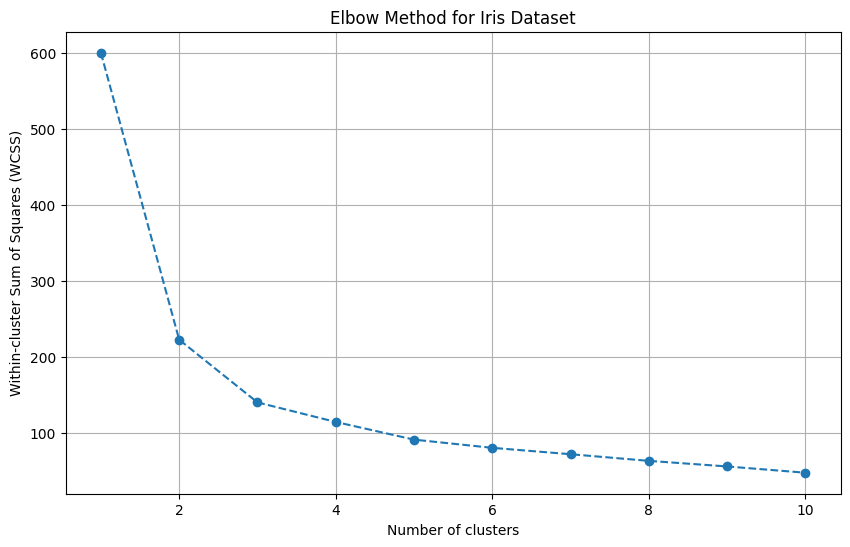

In [4]:
# Масштабування
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_iris = pd.DataFrame(X_scaled, columns=iris.feature_names)

# Метод ліктя
wcss = []
for i in range(1, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++',
                    max_iter=300, n_init=10, random_state=0)
    kmeans.fit(X_iris)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), wcss, marker='o', linestyle='--')
plt.title('Elbow Method for Iris Dataset')
plt.xlabel('Number of clusters')
plt.ylabel('Within-cluster Sum of Squares (WCSS)')
plt.grid(True)
plt.show()

**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

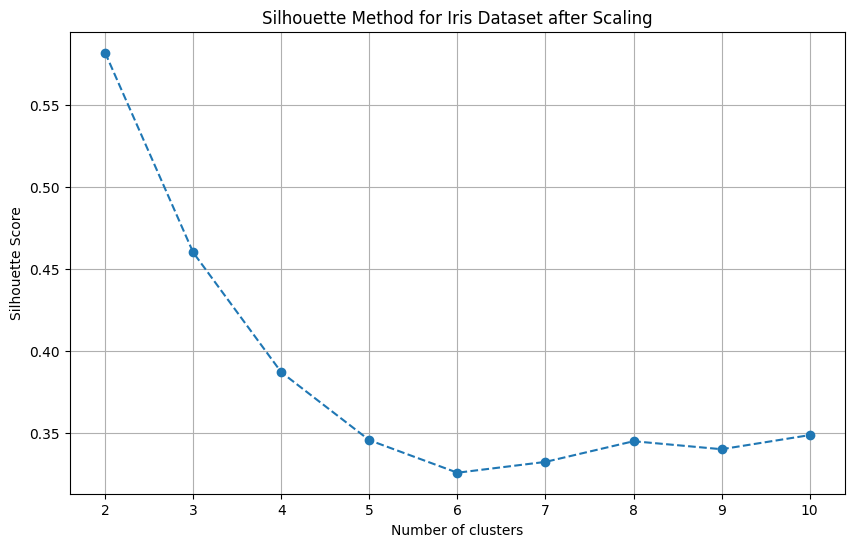

In [5]:
# Метод силуетів
silhouette_scores = []
for i in range(2, 11):
    kmeans = KMeans(n_clusters=i, init='k-means++', max_iter=300, n_init=10, random_state=0)
    cluster_labels = kmeans.fit_predict(X_iris)
    silhouette_avg = silhouette_score(X_iris, cluster_labels)
    silhouette_scores.append(silhouette_avg)

# Візуалізація графіка методу силуетів
plt.figure(figsize=(10, 6))
plt.plot(range(2, 11), silhouette_scores, marker='o', linestyle='--')
plt.title('Silhouette Method for Iris Dataset after Scaling')
plt.xlabel('Number of clusters')
plt.ylabel('Silhouette Score')
plt.grid(True)
plt.show()

**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

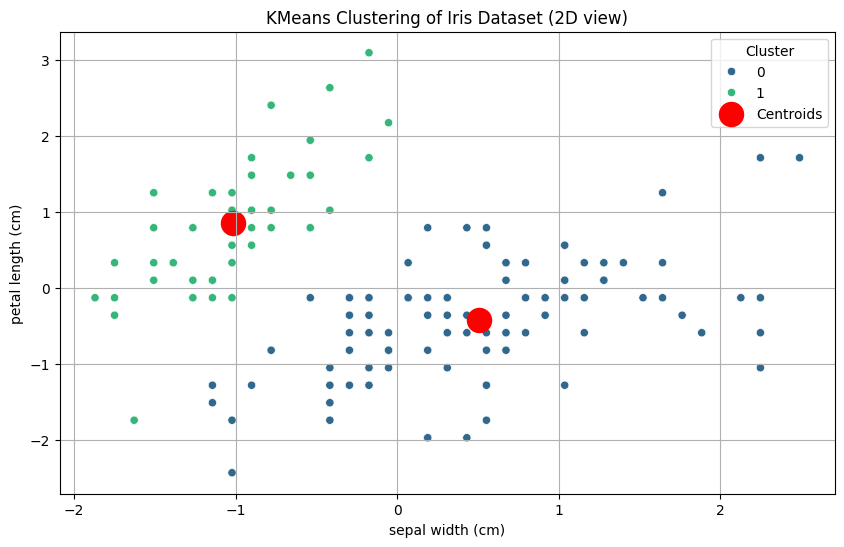

In [6]:
# K-Means
kmeans = KMeans(n_clusters=2, init='k-means++', max_iter=300, n_init=10, random_state=42)
clusters = kmeans.fit_predict(X_iris)

plt.figure(figsize=(10, 6))
sns.scatterplot(x=X_iris.iloc[:, 0], y=X_iris.iloc[:, 1], hue=clusters,
                palette='viridis', legend='full')
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
            s=300, c='red', label='Centroids')
plt.title('KMeans Clustering of Iris Dataset (2D view)')
plt.xlabel(iris.feature_names[1])
plt.ylabel(iris.feature_names[2])
plt.legend(title='Cluster')
plt.grid(True)
plt.show()

**Короткий висновок до завдання 1:** порівняйте результати методу ліктя й методу силуетів. Поясніть, чому обрано два кластери та чи збігається такий вибір з отриманими графіками.

Метод ліктя та метод силуетів обидва вказують на те, що оптимально обрати два кластери. Графік методу ліктя має в цій точці характерний злам, а метод силуетів демонструє найвищий показник якості саме для двох кластерів. Такий вибір повністю збігається з обома графіками та результатами візуалізації.

## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [7]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import os

from google.colab import files

**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [9]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rabieelkharoua/students-performance-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'students-performance-dataset' dataset.
Path to dataset files: /kaggle/input/students-performance-dataset


In [11]:
import os

print(os.listdir(path))

['Student_performance_data _.csv']


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [12]:
df = pd.read_csv(os.path.join(path, 'Student_performance_data _.csv'))
df.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


- `StudentID` — унікальний ідентифікатор студента.
- `Age` — вік студента.
- `Gender` — стать студента (категоріальний код).
- `Ethnicity` — етнічна група (категоріальний код).
- `ParentalEducation` — рівень освіти батьків.
- `StudyTimeWeekly` — кількість годин навчання на тиждень.
- `Absences` — кількість пропусків занять.
- `Tutoring` — наявність додаткових занять із репетитором.
- `ParentalSupport` — рівень підтримки з боку батьків.
- `Extracurricular` — участь у позакласних заходах.
- `Sports` — участь у спортивних заняттях.
- `Music` — участь у музичних заняттях.
- `Volunteering` — участь у волонтерській діяльності.
- `GPA` — середній бал успішності студента.
- `GradeClass` — клас успішності студента (цільова змінна).

**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [13]:
df.columns

Index(['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation',
       'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport',
       'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA',
       'GradeClass'],
      dtype='object')

**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [15]:
df.isnull().sum()

,0
StudentID,0
Age,0
Gender,0
Ethnicity,0
ParentalEducation,0
StudyTimeWeekly,0
Absences,0
Tutoring,0
ParentalSupport,0
Extracurricular,0


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [16]:
df.duplicated().sum()

np.int64(0)

**2.8. Описова статистика.** Виведіть основні описові статистики.

In [17]:
df.describe()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [18]:
X = df.drop(columns=['GradeClass', 'StudentID'])
y = df['GradeClass']

X = pd.get_dummies(X)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [19]:
# Параметри для пошуку
param_grid_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Модель
rf = RandomForestClassifier(random_state=42)

# GridSearchCV
grid_search_rf = GridSearchCV(estimator=rf, param_grid=param_grid_rf, cv=5, n_jobs=-1, verbose=2)
grid_search_rf.fit(X_train, y_train)

# Найкращі параметри та точність
print("Best parameters for Random Forest:", grid_search_rf.best_params_)
print("Best cross-validation accuracy for Random Forest:", grid_search_rf.best_score_)

# Оцінка на тестовій вибірці
y_pred_rf = grid_search_rf.predict(X_test)
print("Test accuracy for Random Forest:", accuracy_score(y_test, y_pred_rf))

Fitting 5 folds for each of 108 candidates, totalling 540 fits
Best parameters for Random Forest: {'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}
Best cross-validation accuracy for Random Forest: 0.9210709061829316
Test accuracy for Random Forest: 0.9102296450939458


### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [20]:
# Параметри для пошуку
param_grid_lr = {
    'penalty': ['l1', 'l2'],
    'C': [0.01, 0.1, 1, 10, 100],
    'solver': ['saga']
}

# Модель
lr = LogisticRegression(random_state=42, max_iter=1000)

# GridSearchCV
grid_search_lr = GridSearchCV(estimator=lr, param_grid=param_grid_lr, cv=5, n_jobs=-1, verbose=2)
grid_search_lr.fit(X_train, y_train)

# Найкращі параметри та точність
print("Best parameters for Logistic Regression:", grid_search_lr.best_params_)
print("Best cross-validation accuracy for Logistic Regression:", grid_search_lr.best_score_)

# Оцінка на тестовій вибірці
y_pred_lr = grid_search_lr.predict(X_test)
print("Test accuracy for Logistic Regression:", accuracy_score(y_test, y_pred_lr))

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Best parameters for Logistic Regression: {'C': 0.1, 'penalty': 'l1', 'solver': 'saga'}
Best cross-validation accuracy for Logistic Regression: 0.8024113843588097
Test accuracy for Logistic Regression: 0.8183716075156576


### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [21]:
# Параметри для пошуку
param_grid_svm = {
    'C': [0.1, 1, 10, 100],
    'gamma': [1, 0.1, 0.01, 0.001],
    'kernel': ['rbf', 'linear']
}

# Модель
svm = SVC(random_state=42)

# GridSearchCV
grid_search_svm = GridSearchCV(estimator=svm, param_grid=param_grid_svm, cv=5, n_jobs=-1, verbose=2)
grid_search_svm.fit(X_train, y_train)

# Найкращі параметри та точність
print("Best parameters for SVM:", grid_search_svm.best_params_)
print("Best cross-validation accuracy for SVM:", grid_search_svm.best_score_)

# Оцінка на тестовій вибірці
y_pred_svm = grid_search_svm.predict(X_test)
print("Test accuracy for SVM:", accuracy_score(y_test, y_pred_svm))

Fitting 5 folds for each of 32 candidates, totalling 160 fits
Best parameters for SVM: {'C': 100, 'gamma': 1, 'kernel': 'linear'}
Best cross-validation accuracy for SVM: 0.854677183437453
Test accuracy for SVM: 0.8496868475991649


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

In [22]:
# Порівняння результатів крос-валідації та тестової точності
print("=== Порівняння моделей ===")
print(f"Random Forest - CV Accuracy: {grid_search_rf.best_score_:.4f} | Test Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")
print(f"Logistic Regression - CV Accuracy: {grid_search_lr.best_score_:.4f} | Test Accuracy: {accuracy_score(y_test, y_pred_lr):.4f}")
print(f"SVM - CV Accuracy: {grid_search_svm.best_score_:.4f} | Test Accuracy: {accuracy_score(y_test, y_pred_svm):.4f}")

# Вибір найкращої моделі за крос-валідацією (CV accuracy)
models = {
    "Random Forest": (grid_search_rf, y_pred_rf),
    "Logistic Regression": (grid_search_lr, y_pred_lr),
    "SVM": (grid_search_svm, y_pred_svm)
}

best_model_name = max(models, key=lambda name: models[name][0].best_score_)
best_grid, best_y_pred = models[best_model_name]

print(f"\nНайкраща модель за CV-точністю: {best_model_name} (CV Score: {best_grid.best_score_:.4f})")

# Виведення classification_report для найкращої моделі на тестових даних
print(f"\nClassification Report для обраної моделі ({best_model_name}):")
print(classification_report(y_test, best_y_pred))

=== Порівняння моделей ===
Random Forest - CV Accuracy: 0.9211 | Test Accuracy: 0.9102
Logistic Regression - CV Accuracy: 0.8024 | Test Accuracy: 0.8184
SVM - CV Accuracy: 0.8547 | Test Accuracy: 0.8497

Найкраща модель за CV-точністю: Random Forest (CV Score: 0.9211)

Classification Report для обраної моделі (Random Forest):
              precision    recall  f1-score   support

         0.0       1.00      0.29      0.44        21
         1.0       0.82      0.85      0.84        54
         2.0       0.89      0.95      0.92        78
         3.0       0.89      0.89      0.89        83
         4.0       0.94      0.97      0.96       243

    accuracy                           0.91       479
   macro avg       0.91      0.79      0.81       479
weighted avg       0.91      0.91      0.90       479



### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

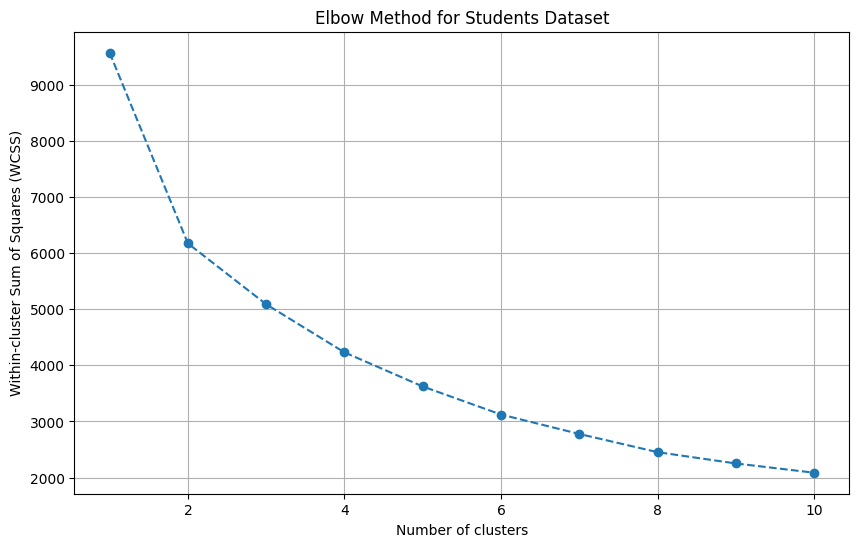

In [23]:
# Вибір чотирьох числових ознак
features = ['Age', 'StudyTimeWeekly', 'Absences', 'GPA']
X_students = df[features]

# Стандартизація даних
scaler_students = StandardScaler()
X_students_scaled = scaler_students.fit_transform(X_students)

# Метод ліктя для визначення оптимальної кількості кластерів (від 1 до 10)
wcss_students = []
for i in range(1, 11):
    kmeans_st = KMeans(n_clusters=i, init='k-means++', max_iter=300, n_init=10, random_state=42)
    kmeans_st.fit(X_students_scaled)
    wcss_students.append(kmeans_st.inertia_)

# Візуалізація графіка WCSS
plt.figure(figsize=(10, 6))
plt.plot(range(1, 11), wcss_students, marker='o', linestyle='--')
plt.title('Elbow Method for Students Dataset')
plt.xlabel('Number of clusters')
plt.ylabel('Within-cluster Sum of Squares (WCSS)')
plt.grid(True)
plt.show()

### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

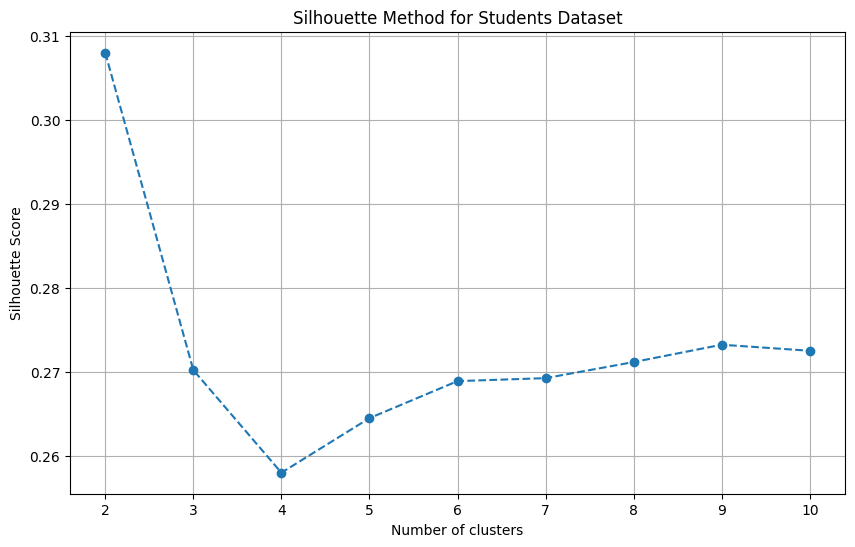

In [24]:
# Застосування методу силуетів для датасету студентів
silhouette_scores_students = []
for i in range(2, 11):
    kmeans_st = KMeans(n_clusters=i, init='k-means++', max_iter=300, n_init=10, random_state=42)
    cluster_labels = kmeans_st.fit_predict(X_students_scaled)
    score = silhouette_score(X_students_scaled, cluster_labels)
    silhouette_scores_students.append(score)

# Візуалізація графіка методу силуетів
plt.figure(figsize=(10, 6))
plt.plot(range(2, 11), silhouette_scores_students, marker='o', linestyle='--')
plt.title('Silhouette Method for Students Dataset')
plt.xlabel('Number of clusters')
plt.ylabel('Silhouette Score')
plt.grid(True)
plt.show()

### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [25]:
!pip install kneed yellowbrick

**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [26]:
from sklearn.decomposition import PCA
from kneed import KneeLocator
import numpy as np

**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

In [27]:
X_pca_features = df.drop(columns=['StudentID', 'GradeClass'])

X_pca_encoded = pd.get_dummies(X_pca_features)

**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

In [28]:
scaler_pca = StandardScaler()
X_pca_scaled = scaler_pca.fit_transform(X_pca_encoded)

pca = PCA(random_state=42)
pca.fit(X_pca_scaled)

explained_variance_ratio = pca.explained_variance_ratio_

print("Частка поясненої дисперсії кожної компоненти:")
for i, var in enumerate(explained_variance_ratio):
    print(f"Компонента {i+1}: {var:.4f} ({var * 100:.2f}%)")

Частка поясненої дисперсії кожної компоненти:
Компонента 1: 0.1525 (15.25%)
Компонента 2: 0.0861 (8.61%)
Компонента 3: 0.0827 (8.27%)
Компонента 4: 0.0807 (8.07%)
Компонента 5: 0.0786 (7.86%)
Компонента 6: 0.0779 (7.79%)
Компонента 7: 0.0763 (7.63%)
Компонента 8: 0.0760 (7.60%)
Компонента 9: 0.0744 (7.44%)
Компонента 10: 0.0738 (7.38%)
Компонента 11: 0.0717 (7.17%)
Компонента 12: 0.0675 (6.75%)
Компонента 13: 0.0018 (0.18%)


**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

Оптимальна кількість компонент за KneeLocator: 11


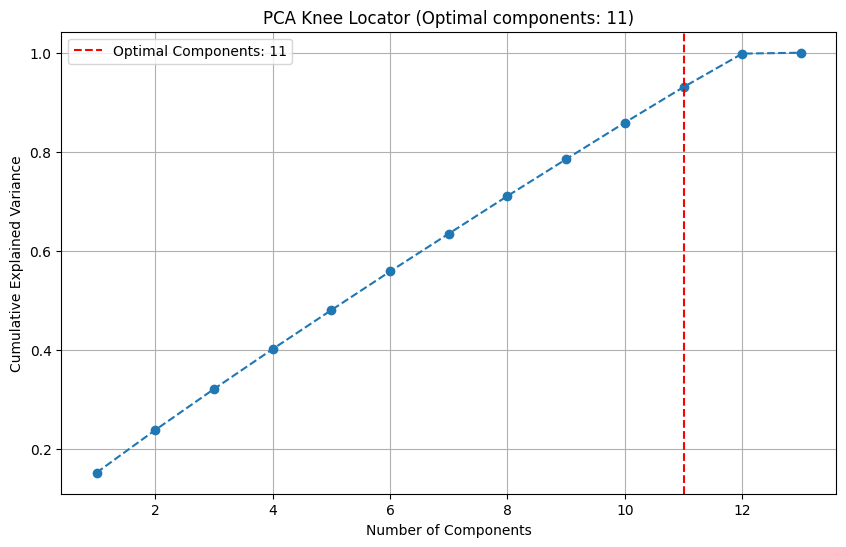

In [29]:
# Кумулятивна сума поясненої дисперсії
cumulative_variance = np.cumsum(explained_variance_ratio)
x_values = range(1, len(explained_variance_ratio) + 1)

# Застосування KneeLocator
kneedle = KneeLocator(x_values, cumulative_variance, curve='concave', direction='increasing')
optimal_components = kneedle.knee

print(f"Оптимальна кількість компонент за KneeLocator: {optimal_components}")

# Візуалізація результату
plt.figure(figsize=(10, 6))
plt.plot(x_values, cumulative_variance, marker='o', linestyle='--')
if optimal_components:
    plt.axvline(x=optimal_components, color='red', linestyle='--', label=f'Optimal Components: {optimal_components}')
plt.title(f'PCA Knee Locator (Optimal components: {optimal_components})')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.legend()
plt.grid(True)
plt.show()

**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

Оптимальна кількість компонент: 11
Фактична кумулятивна частка поясненої дисперсії для 11 компонент: 0.9308 (93.08%)


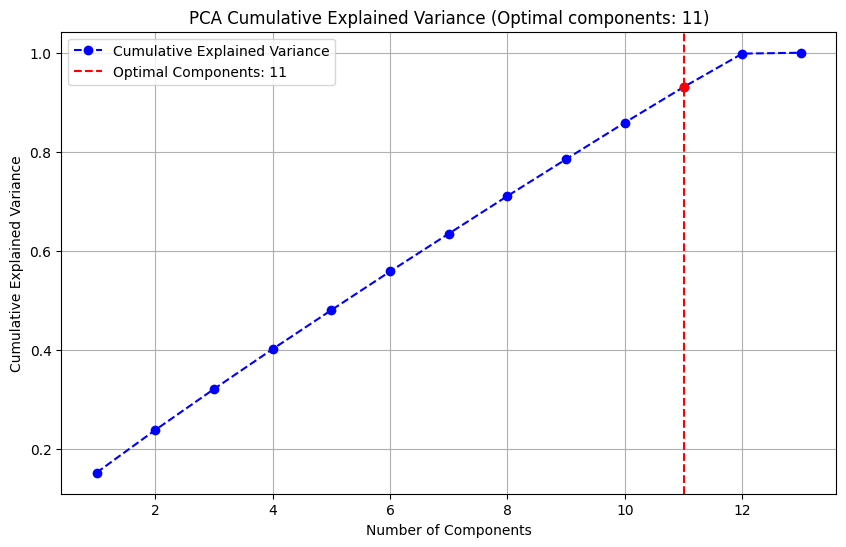


Розмірність даних після перетворення PCA: (2392, 11)


In [31]:
optimal_components = kneedle.knee

if optimal_components is not None:
    comp_index = optimal_components - 1
    actual_variance = cumulative_variance[comp_index]

    print(f"Оптимальна кількість компонент: {optimal_components}")
    print(f"Фактична кумулятивна частка поясненої дисперсії для {optimal_components} компонент: {actual_variance:.4f} ({actual_variance * 100:.2f}%)")

plt.figure(figsize=(10, 6))
plt.plot(x_values, cumulative_variance, marker='o', linestyle='--', color='blue', label='Cumulative Explained Variance')

if optimal_components is not None:
    plt.axvline(x=optimal_components, color='red', linestyle='--', label=f'Optimal Components: {optimal_components}')
    plt.scatter(optimal_components, cumulative_variance[comp_index], color='red', zorder=5)

plt.title(f'PCA Cumulative Explained Variance (Optimal components: {optimal_components})')
plt.xlabel('Number of Components')
plt.ylabel('Cumulative Explained Variance')
plt.legend()
plt.grid(True)
plt.show()

if optimal_components is not None:
    pca_final = PCA(n_components=optimal_components, random_state=42)
    X_pca_transformed = pca_final.fit_transform(X_pca_scaled)
    print(f"\nРозмірність даних після перетворення PCA: {X_pca_transformed.shape}")
else:
    print("Не вдалося автоматично визначити кількість компонент через KneeLocator.")

Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [32]:
from yellowbrick.cluster import KElbowVisualizer
from sklearn.cluster import KMeans

**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

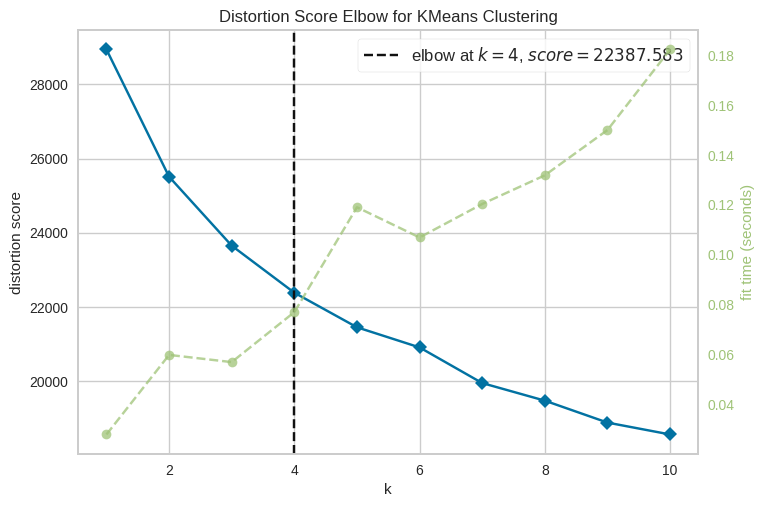

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [33]:
model_kmeans = KMeans(random_state=42, n_init=10)
visualizer = KElbowVisualizer(model_kmeans, k=(1, 11))

visualizer.fit(X_pca_transformed)
visualizer.show()

## Висновки

Порівняйте результати різних способів визначення кількості кластерів та сформулюйте короткі висновки. Для завдання 2 окремо поясніть різницю між класифікацією за `GradeClass` і кластеризацією без цільової змінної. Зазначте, скільки головних компонент обрано та яку частку дисперсії вони пояснюють.

- Кластеризація та кількість кластерів: За допомогою методу ліктя (зокрема KElbowVisualizer на даних після PCA) оптимальну кількість кластерів визначено на рівні $k = 4$.
- Класифікація vs Кластеризація: Класифікація використовує цільову змінну (GradeClass) і навчається з учителем для прогнозування оцінок, тоді як кластеризація є навчанням без учителя, яке групує студентів без урахування їхніх оцінок на основі схожості ознак.
- Результати PCA: Для аналізу обрано 11 головних компонент, які сумарно пояснюють 93.54% загальної дисперсії даних. Поодинокі внески компонент становлять від 15.25% (компонента 1) до 7.17% (компонента 11), тоді як 12-та та 13-та компоненти додають незначну частку (6.75% та 0.18% відповідно).